# TRISO fuel, step by step

This notebook models TRISO particle fuel in ARMI and runs it in OpenMC with every particle
drawn. It uses the LEUPRO-1 pebble cell of the LEU-HTR PROTEUS benchmark (see
{doc}`benchmarks`): one 6 cm pebble holding 9,394 coated particles, small enough to run in a few
minutes. Compacts in a prismatic block work the same way; the MHTGR-350 inputs are a full
example.

It was run with the ARMI fork, OpenMC 0.15.3 (in docker) and ENDF/B-VIII.1. To rerun it, point
`DATA` at your own `cross_sections.xml`.

In [1]:
import contextlib
import io
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openmc
import pandas as pd

import armi
from armi_openmc.app import OpenMCApp

if not armi.isConfigured():
    with contextlib.redirect_stdout(io.StringIO()):  # the start-up banner
        armi.configure(OpenMCApp())

from armi import runLog, settings
from armi.reactor import blueprints

from armi_openmc import mgxs, runner
from armi_openmc.options import OpenMCOptions

EXAMPLE = Path("../examples/leupro-1")
RUNS = Path("_notebook-runs").resolve()
DATA = "/mnt/storage/nuclear_data/openmc/endfb-viii.1-hdf5/cross_sections.xml"
runLog.setVerbosity("error")  # ARMI's progress messages

# One color per model, used in every plot (a validated categorical palette)
EXPLICIT, SMEARED, HOMOGENEOUS = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

## 1. Describe the particles in the blueprints

A top-level `particles:` section defines each kind of particle as spherical layers, innermost
first. A component then holds those particles at a packing fraction, and its own material is
the matrix between them. Here is the LEUPRO-1 particle and the pebble that holds it:

In [2]:
text = (EXAMPLE / "leupro1-blueprints.yaml").read_text()
start = text.index("particles:")
print(text[start : text.index("assemblies:")])

particles:
    coated particle:
        kernel:
            material: Custom
            isotopics: UO2 kernel
            od: 0.0502
            flags: fuel depletable
        buffer:
            material: Custom
            isotopics: buffer
            od: 0.0685
        inner PyC:
            material: Custom
            isotopics: PyC
            od: 0.07648
        SiC:
            material: Custom
            isotopics: SiC
            od: 0.08354
        outer PyC:
            material: Custom
            isotopics: PyC
            od: 0.09154
blocks:
    pebble cell: &block_pebble
        flags: fuel
        fuel zone:
            shape: Sphere
            material: Custom
            isotopics: graphite
            Tinput: 20.0
            Thot: 20.0
            id: 0.0
            od: 5.0
            mult: 1
            particles: coated particle
            packingFraction: 0.0576441  # 9,393.6 particles
        graphite shell:
            shape: Sphere
            material

The pebble is a *spherical block*. Its largest component is a `Sphere`, so it becomes a
`SphericalBlock`: concentric spheres for the fuel zone, the graphite shell, and the pebble's
share of the bed around it.

## 2. Build the block in ARMI

In [3]:
cs = settings.Settings(str(EXAMPLE / "leupro1-explicit.yaml"))
bp = blueprints.Blueprints.load(text)
with contextlib.redirect_stdout(io.StringIO()):
    pebble = bp.constructAssem(cs, "pebble")[0]
pebble.p.xsType, pebble.p.envGroup = "A", "A"
print(type(pebble).__name__, f"diameter {pebble.getPitch()} cm")

SphericalBlock diameter 7.5918 cm


Every particle layer is a component of the block, a `ParticleLayer` named after its host. Each
has its own material and composition, so masses, number densities, homogenization, depletion
and the database all see it. In a sphere a layer's `mult` is the number of particles. In a
compact, whose particles fill a prism, it is particles per centimeter of block height.

In [4]:
rows = []
for c in pebble:
    rows.append({
        "component": c.name,
        "type": type(c).__name__,
        "outer diameter (cm)": c.getDimension("od"),
        "particles": c.getParticleCount() if hasattr(c, "getParticleCount") else None,
        "volume (cm3)": c.getVolume(),
        "U-235 (g)": c.getMass("U235"),
    })
table = pd.DataFrame(rows).set_index("component")
table.style.format({"outer diameter (cm)": "{:.5g}", "particles": "{:,.1f}",
                    "volume (cm3)": "{:.4f}", "U-235 (g)": "{:.4f}"}, na_rep="")

,type,outer diameter (cm),particles,volume (cm3),U-235 (g)
component,,,,,
fuel zone,Sphere,5,,61.6770,0.0000
graphite shell,Sphere,6,,47.6475,0.0000
moderator and air,Sphere,7.5918,,116.0068,0.0000
fuel zone kernel,ParticleLayer,0.0502,"9,393.6",0.6222,0.9999
fuel zone buffer,ParticleLayer,0.0685,"9,393.6",0.9587,0.0000
fuel zone inner PyC,ParticleLayer,0.07648,"9,393.6",0.6194,0.0000
fuel zone SiC,ParticleLayer,0.08354,"9,393.6",0.6673,0.0000
fuel zone outer PyC,ParticleLayer,0.09154,"9,393.6",0.9052,0.0000


In [5]:
zone = pebble.getComponentByName("fuel zone")
particles = sum(c.getVolume() for c in zone.particleLayers)
print(f"packing fraction  {particles / (zone.getVolume() + particles):.5f}"
      f"   (blueprint: {zone.p.packingFraction})")
print(f"fuel zone volume  {zone.getVolume() + particles:.5f} cm3 = matrix + particles"
      f"   (a 5 cm sphere: {np.pi / 6 * 5**3:.5f})")
print(f"cell volume       {pebble.getVolume():.5f} cm3"
      f"   (a {pebble.getPitch()} cm sphere: {np.pi / 6 * pebble.getPitch()**3:.5f})")

packing fraction  0.05764   (blueprint: 0.0576441)
fuel zone volume  65.44985 cm3 = matrix + particles   (a 5 cm sphere: 65.44985)
cell volume       229.10412 cm3   (a 7.5918 cm sphere: 229.10412)


The host is the matrix. Its volume is the fuel zone less its particles, so matrix plus particles
fill the zone exactly, and every volume is that of the spheres.

## 3. One coated particle

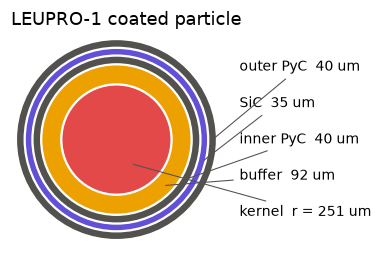

In [6]:
layers = zone.particleLayers
colors = ["#e34948", "#eda100", "#52514e", "#6250d6", "#52514e"]
fig, ax = plt.subplots(figsize=(4.2, 4.2))
for c, color in reversed(list(zip(layers, colors))):
    r = c.getDimension("od") / 2 * 1e4  # micrometers
    ax.add_patch(plt.Circle((0, 0), r, color=color, ec="white", lw=1.5))
for k, c in enumerate(layers):
    r_in = c.getDimension("id") / 2 * 1e4
    r_out = c.getDimension("od") / 2 * 1e4
    label = c.name.removeprefix("fuel zone ")
    text = f"{label}  {r_out - r_in:.0f} um" if r_in else f"{label}  r = {r_out:.0f} um"
    angle = np.radians(-60 + 15 * k)  # point at each layer from a different angle
    mid = (r_in + r_out) / 2
    ax.annotate(text, xy=(mid * np.cos(angle), mid * np.sin(angle)), xytext=(560, -330 + 165 * k),
                fontsize=9, va="center",
                arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.7))
ax.set(xlim=(-480, 1150), ylim=(-480, 480), aspect="equal")
ax.axis("off")
ax.set_title("LEUPRO-1 coated particle", loc="left")
plt.show()

## 4. The OpenMC model

`XSModelBuilder` turns the block into an OpenMC model:

- every sphere becomes a cell, and the outer sphere has a white boundary;
- the 9,393.6 particles round to 9,394, which `openmc.model.pack_spheres` places at random in
  the fuel zone;
- `openmc.model.create_triso_lattice` sorts the particles onto a Cartesian mesh, so a neutron
  only tests the particles in its own mesh element.

`openmcParticleModel` switches between drawing every particle (`explicit`) and smearing them
into the fuel zone (`homogenized`).

In [7]:
def build(particleModel="explicit", blockModel="heterogeneous", **stats):
    opts = OpenMCOptions.fromSettings(
        cs, crossSections=DATA, runDir=str(RUNS), particleModel=particleModel,
        blockModel=blockModel, **stats)
    nuclides = {n for n, d in pebble.getNumberDensities().items() if d > 0}
    return mgxs.XSModelBuilder(opts).build(pebble, "AA", nuclides), opts

xs, opts = build()
cells = xs.model.geometry.get_all_cells().values()
print(f"{len(xs.model.materials)} materials, {len(cells):,} cells, "
      f"{sum(isinstance(c, openmc.model.TRISO) for c in cells):,} of them TRISO cells "
      "(a particle crossing mesh elements is in each of them)")

[info] OpenMC: packed 9394 particles in fuel zone (packing fraction 0.0576) on a 14^3 mesh


7 materials, 21,343 cells, 18,588 of them TRISO cells (a particle crossing mesh elements is in each of them)


OpenMC's plot mode draws slices of the geometry it will track, colored by material:

[info] Plotting the geometry with OpenMC (docker) in /mnt/storage/repos/armi-openmc-plugin/doc/_notebook-runs/plot-explicit


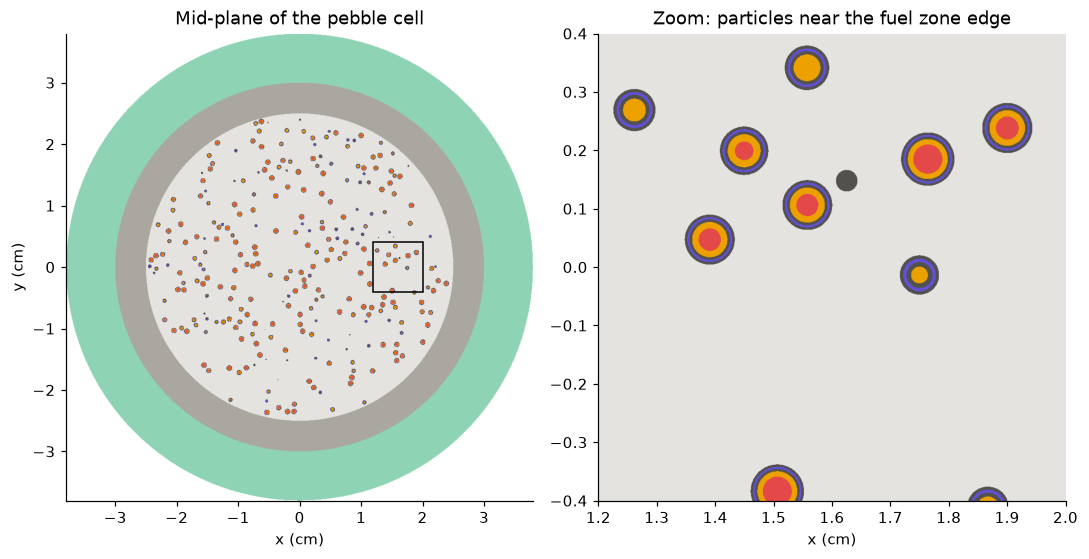

In [8]:
def color(material):
    name = material.name
    for key, value in [("kernel", "#e34948"), ("buffer", "#eda100"), ("PyC", "#52514e"),
                       ("SiC", "#6250d6"), ("moderator", "#8fd3b5"), ("matrix", "#e4e3df"),
                       ("", "#a9a7a0")]:
        if key in name:
            return tuple(int(value[i : i + 2], 16) for i in (1, 3, 5))  # OpenMC wants RGB

def plotSlices(xs, opts, name):
    workdir = RUNS / f"plot-{name}"
    workdir.mkdir(parents=True, exist_ok=True)
    colors = {m: color(m) for m in xs.model.materials}
    whole = openmc.Plot(name="whole")
    whole.width, whole.pixels = (7.6, 7.6), (900, 900)
    zoom = openmc.Plot(name="zoom")
    zoom.origin, zoom.width, zoom.pixels = (1.6, 0.0, 0.0), (0.8, 0.8), (900, 900)
    for p in (whole, zoom):
        p.basis, p.color_by, p.colors, p.background = "xy", "material", colors, "white"
    xs.model.plots = openmc.Plots([whole, zoom])
    xs.model.export_to_model_xml(workdir / "model.xml")
    runner.run(opts, workdir, args=["-p"], echo=False)
    return [plt.imread(workdir / f"plot_{p.id}.png") for p in (whole, zoom)]

whole, zoom = plotSlices(xs, opts, "explicit")
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 5))
a.imshow(whole, extent=(-3.8, 3.8, -3.8, 3.8))
a.add_patch(plt.Rectangle((1.2, -0.4), 0.8, 0.8, fill=False, ec="black", lw=1))
a.set(title="Mid-plane of the pebble cell", xlabel="x (cm)", ylabel="y (cm)")
b.imshow(zoom, extent=(1.2, 2.0, -0.4, 0.4))
b.set(title="Zoom: particles near the fuel zone edge", xlabel="x (cm)")
for ax in (a, b):
    ax.grid(False)
plt.tight_layout()
plt.show()

The fuel zone (light matrix speckled with particles) sits inside the darker graphite shell,
inside the smeared bed (green). The zoom shows each particle's kernel (red) and coatings, cut at whatever
height the slice crosses them. No particle crosses the edge of the fuel zone.

## 5. How the particles are packed

`pack_spheres` uses random sequential addition, and for a dense packing a jammed-packing step
after it. It places centers uniformly, at least one particle radius from the boundary.
Counting the centers in 25 spherical shells of equal volume, out to that radius, shows that:

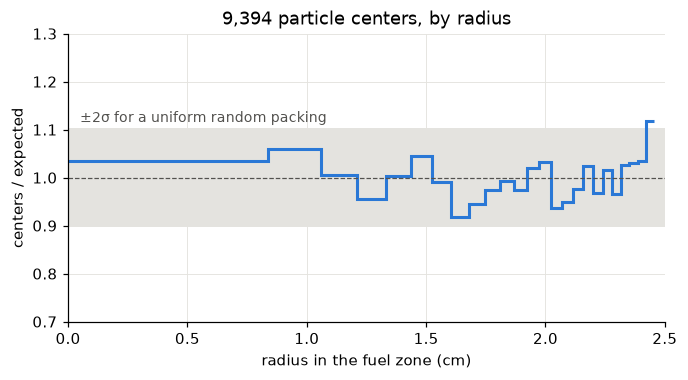

In [9]:
(packing,) = (RUNS / "particle-packings").glob("*.npy")
centers = np.load(packing)
r = np.linalg.norm(centers, axis=1)
reach = 2.5 - 0.09154 / 2  # a center stays one particle radius inside the zone
edges = reach * np.linspace(0, 1, 26) ** (1 / 3)  # 25 shells of equal volume
counts = np.histogram(r, edges)[0]
expected = len(centers) / 25

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axhspan(1 - 2 / np.sqrt(expected), 1 + 2 / np.sqrt(expected), color="#e4e3df", lw=0)
ax.stairs(counts / expected, edges, color=EXPLICIT, lw=2, baseline=None)
ax.axhline(1, color="#52514e", lw=0.8, ls="--")
ax.annotate("±2σ for a uniform random packing", (0.05, 1 + 2 / np.sqrt(expected)),
            xytext=(0, 4), textcoords="offset points", fontsize=9, color="#52514e")
ax.set(xlabel="radius in the fuel zone (cm)", ylabel="centers / expected",
       xlim=(0, 2.5), ylim=(0.7, 1.3), title=f"{len(centers):,} particle centers, by radius")
plt.show()

Every shell holds what a uniform random packing would put there, within its statistics (one
shell in twenty lands outside ±2σ by chance; here it is the outermost). A
packing fraction of 5.8% is dilute, so there is no layering at the wall: the density is flat
out to the edge.

## 6. Run it: explicit particles against smeared ones

The same block runs three ways. The fuel zone is drawn with every particle, then with its
particles smeared into it (the zone stays a sphere inside the shell), then with the whole cell
smeared into one material. Each case adds a fine-group flux tally and a U-238 capture tally to
the cross-section tallies the plugin always makes. The statistics here are lighter than in
{doc}`benchmarks` (10,000 × 150), so each case runs in a few minutes.

In [10]:
FINE = np.logspace(-3, 7.3, 501)  # eV

def run(name, **model):
    xs, opts = build(particles=10_000, batches=150, inactive=30, **model)
    energy = openmc.EnergyFilter(FINE)
    flux = openmc.Tally(name="fine flux")
    flux.filters, flux.scores = [energy], ["flux"]
    capture = openmc.Tally(name="U238 capture")
    capture.filters, capture.nuclides, capture.scores = [energy], ["U238"], ["(n,gamma)"]
    xs.model.tallies += [flux, capture]
    workdir = RUNS / name
    workdir.mkdir(parents=True, exist_ok=True)
    xs.model.export_to_model_xml(workdir / "model.xml")
    statepoint = runner.run(opts, workdir, echo=False)
    with openmc.StatePoint(statepoint) as sp:
        out = {"k": sp.keff,
               "flux": sp.get_tally(name="fine flux").mean.ravel(),
               "capture": sp.get_tally(name="U238 capture").mean.ravel()}
    out["constants"], _ = mgxs.reduce(xs, statepoint)
    return out

results = {
    "explicit": run("explicit"),
    "smeared": run("smeared", particleModel="homogenized"),
    "homogeneous": run("homogeneous", blockModel="homogenized"),
}
for name, res in results.items():
    print(f"{name:12s} k-inf = {res['k'].n:.5f} +/- {res['k'].s:.5f}")

[info] OpenMC: packed 9394 particles in fuel zone (packing fraction 0.0576) on a 14^3 mesh


[info] Running OpenMC (docker) in /mnt/storage/repos/armi-openmc-plugin/doc/_notebook-runs/explicit


[info] Running OpenMC (docker) in /mnt/storage/repos/armi-openmc-plugin/doc/_notebook-runs/smeared


[info] Running OpenMC (docker) in /mnt/storage/repos/armi-openmc-plugin/doc/_notebook-runs/homogeneous


explicit     k-inf = 1.71671 +/- 0.00066
smeared      k-inf = 1.62683 +/- 0.00072
homogeneous  k-inf = 1.58280 +/- 0.00084


## 7. Results

### k-infinity

The plot compares the three models with the MCNP references compiled in IAEA-TECDOC-1249 and
J. R. Johnson's MIT thesis (2001). Those references used older nuclear data and a cubic lattice
of particles.

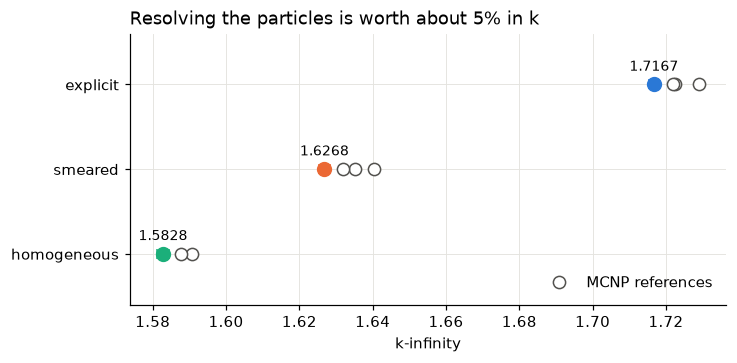

double heterogeneity: explicit / smeared = 1.0552  (references 1.0534-1.0551)


In [11]:
refs = {  # (Johnson ENDF/B-VI, ORNL ENDF/B-V, ECN JEF-2.2)
    "explicit": (1.7226, 1.7219, 1.7291),
    "smeared": (1.6353, 1.6319, 1.6404),
    "homogeneous": (1.5908, 1.5878, None),
}
colors = {"explicit": EXPLICIT, "smeared": SMEARED, "homogeneous": HOMOGENEOUS}
fig, ax = plt.subplots(figsize=(7, 3.2))
for y, (name, res) in enumerate(results.items()):
    ref = [v for v in refs[name] if v]
    ax.plot(ref, [y] * len(ref), "o", mfc="white", mec="#52514e", ms=8,
            label="MCNP references" if y == 0 else None)
    ax.errorbar(res["k"].n, y, xerr=2 * res["k"].s, fmt="o", color=colors[name], ms=9, capsize=3)
    ax.annotate(f"{res['k'].n:.4f}", (res["k"].n, y), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=9)
ax.set_yticks(range(3), [f"{n}" for n in results])
ax.set(xlabel="k-infinity", ylim=(-0.6, 2.6))
ax.invert_yaxis()
ax.legend(loc="lower right", frameon=False)
ax.set_title("Resolving the particles is worth about 5% in k", loc="left")
plt.show()

ratio = results["explicit"]["k"].n / results["smeared"]["k"].n
print(f"double heterogeneity: explicit / smeared = {ratio:.4f}  (references 1.0534-1.0551)")

All three models sit about 0.4% below the references, the same amount in the homogeneous cell,
which has no particles at all. That offset is the nuclear data, not the geometry. The ratio of
explicit to smeared cancels most of the data and matches the references.

### Where the 5% comes from

The spectrum has the same shape in all three models: a graphite-moderated thermal peak at
0.07 eV over a 1/E slowing-down plateau. Normalized to the thermal peak, the explicit model has
about 10% less flux above it. Fewer neutrons are lost while slowing down, so relatively more
reach thermal energies.

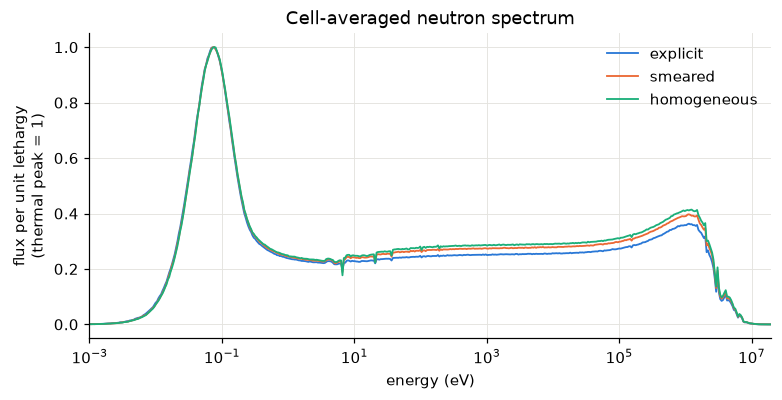

In [12]:
mid = np.sqrt(FINE[1:] * FINE[:-1])
lethargy = np.log(FINE[1:] / FINE[:-1])
fig, ax = plt.subplots(figsize=(8, 3.6))
for name, res in results.items():
    perLethargy = res["flux"] / lethargy
    ax.plot(mid, perLethargy / perLethargy.max(), color=colors[name], lw=1.2, label=name)
ax.set(xscale="log", xlabel="energy (eV)", ylabel="flux per unit lethargy\n(thermal peak = 1)",
       xlim=(1e-3, 2e7), title="Cell-averaged neutron spectrum")
ax.legend(frameon=False)
plt.show()

The difference is in the resonances. In the explicit model the U-238 sits in 0.5 mm kernels.
Near a big resonance the kernel's surface absorbs the neutrons before they reach its interior,
so most U-238 atoms see a depressed flux. This is self-shielding. Smeared into the fuel zone,
the same atoms are spread thin through the graphite, and every one of them sees the full
flux. Capture in U-238, per unit lethargy:

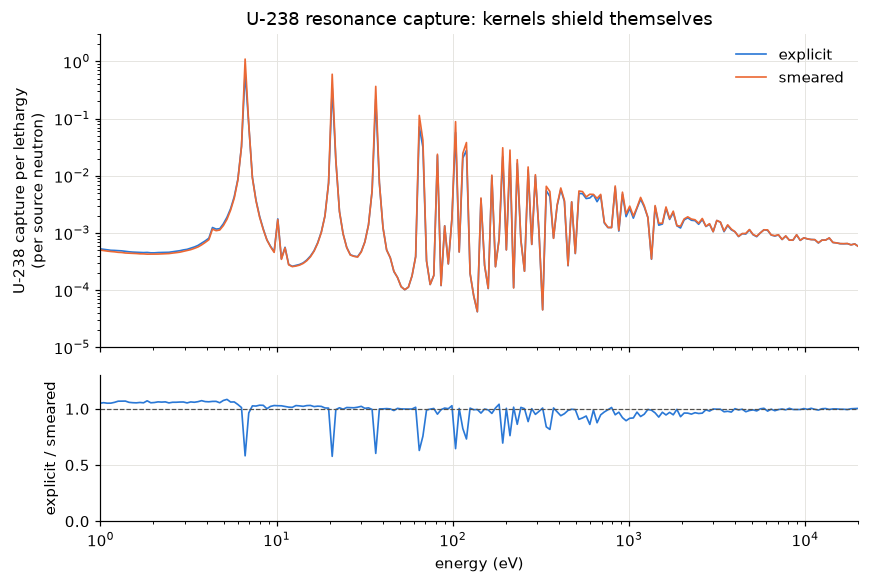

U-238 captures per source neutron: explicit 0.1084, smeared 0.1544 (-30%)


In [13]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 5.4), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 1.4]})
for name in ("explicit", "smeared"):
    res = results[name]
    top.plot(mid, res["capture"] / lethargy, color=colors[name], lw=1.1, label=name)
top.set(xscale="log", yscale="log", ylabel="U-238 capture per lethargy\n(per source neutron)",
        xlim=(1, 2e4), ylim=(1e-5, 3), title="U-238 resonance capture: kernels shield themselves")
top.legend(frameon=False)
ratio = results["explicit"]["capture"] / np.where(results["smeared"]["capture"] > 0,
                                                  results["smeared"]["capture"], np.nan)
bottom.plot(mid, ratio, color=EXPLICIT, lw=1.1)
bottom.axhline(1, color="#52514e", lw=0.8, ls="--")
bottom.set(xscale="log", xlabel="energy (eV)", ylabel="explicit / smeared", ylim=(0, 1.3))
plt.tight_layout()
plt.show()

total = {n: results[n]["capture"].sum() for n in ("explicit", "smeared")}
print(f"U-238 captures per source neutron: explicit {total['explicit']:.4f}, "
      f"smeared {total['smeared']:.4f} ({total['explicit'] / total['smeared'] - 1:+.0%})")

At the peak of each big resonance (6.7, 21, 37 and 66 eV, and the many above) the explicit
model captures about 40% less than the smeared one. Over all energies, U-238 captures 30% fewer
neutrons. Fewer neutrons are lost on the way down, so more survive to cause thermal fissions in
U-235. That is the 5% in k.

### The cross sections ARMI gets

The plugin reduces the same tallies to multigroup microscopic cross sections in an ISOTXS
library. The self-shielding carries through to the library: U-238 capture in ANL33 groups,
explicit against smeared:

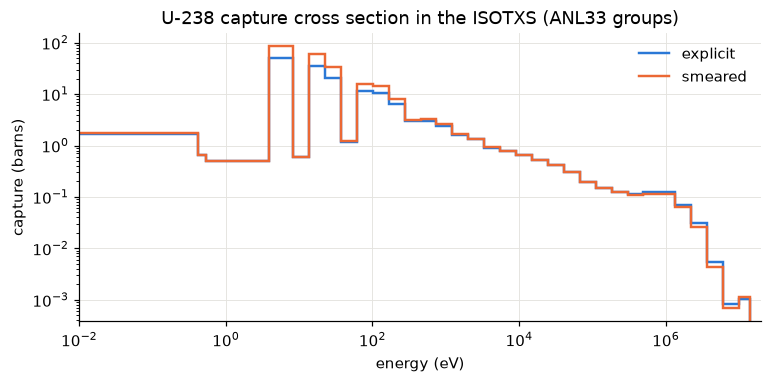

In [14]:
from armi_openmc.energy import upperBounds

upper = upperBounds(opts.groupStructure)  # fast first, eV
lower = np.append(upper[1:], 1e-5)
fig, ax = plt.subplots(figsize=(8, 3.4))
for name in ("explicit", "smeared"):
    sigma = results[name]["constants"]["U238"].capture
    ax.stairs(sigma[::-1], np.append(lower[::-1], upper[0]), color=colors[name], lw=1.6,
              label=name)
ax.set(xscale="log", yscale="log", xlabel="energy (eV)", ylabel="capture (barns)",
       xlim=(1e-2, 2e7), title="U-238 capture cross section in the ISOTXS (ANL33 groups)")
ax.legend(frameon=False)
plt.show()

ANL33 is a fast-reactor structure, so the resolved resonances sit in a handful of wide groups.
In those groups the explicit model's cross section is lower, because the kernels shield
themselves. A deterministic code that reads this library gets the double heterogeneity
without ever seeing a particle. That is the point of making the library from an explicit
model.

## Where to go from here

- Particles in compacts: the {doc}`benchmarks` MHTGR-350 section, and the inputs at
  [partofthething/mhtgr350-armi](https://github.com/partofthething/mhtgr350-armi).
- Settings: `openmcParticleModel`, `openmcParticleSeed` (a different random packing),
  `openmcParticleMeshPitch` and `openmcParticleSegmentLength`, in {doc}`settings`.
- How particles are modeled: {doc}`modeling`.